# Novo modelo de prioridade: receita esperada em 30 dias

Implementação de referência para substituir o score atual do backend (`lead_core` / `lead_trainer`).
Este notebook **não altera** o backend nem os dados: usa o código de features do backend só para leitura e os CSVs originais.

**Problema do score atual:** o modelo prevê *"este deal vai terminar ganho?"* treinando só com deals que já fecharam.
Os deals que ficam parados para sempre nunca entram como exemplo, então o modelo aprende que deal velho é bom
(perdidos morrem rápido, ganhos demoram). O score final é o percentil de `p_win × preço` e acaba sendo quase só o preço.

**Novo alvo:** *"este deal vai virar ganho nos próximos 30 dias, a partir de hoje?"* — observável para **todo** deal aberto,
inclusive os parados (que entram como 0). Score = percentil de `p30 × preço` (receita esperada no mês).

Seções: 1) dados · 2) diagnóstico · 3) modelo novo · 4) backtest contra o atual · 5) regras de negócio propostas · 6) pontuação do pipeline de hoje · 7) checklist de implementação.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
LAB = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(LAB))
from model_lab.backend import use_backend_code, source_data_dir
use_backend_code()                      # backend/src entra no sys.path SOMENTE para leitura

import numpy as np, pandas as pd, lightgbm as lgb
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from lead_core.constants import NUM_FEATURES, CAT_FEATURES, LGBM_PARAMS, TRAIN_START_OFFSET_DAYS
from lead_core.features import open_snapshot, add_history_features
from lead_core.bands import score_from_ev
from lead_trainer.repository import CsvDealRepository
pd.set_option("display.width", 200)

## 1. Dados (mesmo repositório e validação do backend)

In [2]:
df = CsvDealRepository(source_data_dir()).load()
T_NOW = max(df["engage_date"].max(), df["close_date"].max())
print("data de referência:", T_NOW.date())
df["deal_stage"].value_counts()

data de referência: 2017-12-31


deal_stage
Won            4238
Lost           2473
Engaging       1589
Prospecting     500
Name: count, dtype: int64

## 2. Diagnóstico: o que o score atual enxerga vs. o que acontece
Em 4 datas reais, compara o p_win do modelo atual com a taxa real de *ganhou em 30 dias* por idade do deal.

In [3]:
from model_lab.scorers import champion
from model_lab.metrics import outcomes
rows = []
for T in pd.to_datetime(["2017-08-10", "2017-09-07", "2017-10-05", "2017-11-02"]):
    ch = champion(df, T)
    out = outcomes(df, ch.index, T, 30)
    rows.append(pd.DataFrame({"age": ch["age_days"], "p_win_atual": ch["p_win"], "score_atual": ch["score"].astype(float),
                              "real_ganhou_30d": out["won_h"], "preco": ch["list_price"]}))
diag = pd.concat(rows)
diag["faixa"] = pd.cut(diag["age"], [-1, 15, 45, 90, 104, 138, 2000],
                       labels=["0-15", "16-45", "46-90", "91-104", "105-138 parado", "139+ zumbi"])
tab = diag.groupby("faixa", observed=True)[["p_win_atual", "score_atual", "real_ganhou_30d"]].mean()
print("Spearman score x preço:", round(diag[["score_atual", "preco"]].corr("spearman").iloc[0, 1], 3))
tab.round(3)

Spearman score x preço: 0.982


,p_win_atual,score_atual,real_ganhou_30d
faixa,,,
0-15,0.642,46.533,0.149
16-45,0.676,50.248,0.081
46-90,0.680,50.721,0.204
91-104,0.677,48.410,0.156
105-138 parado,0.702,55.207,0.079
139+ zumbi,0.707,NaN,0.000


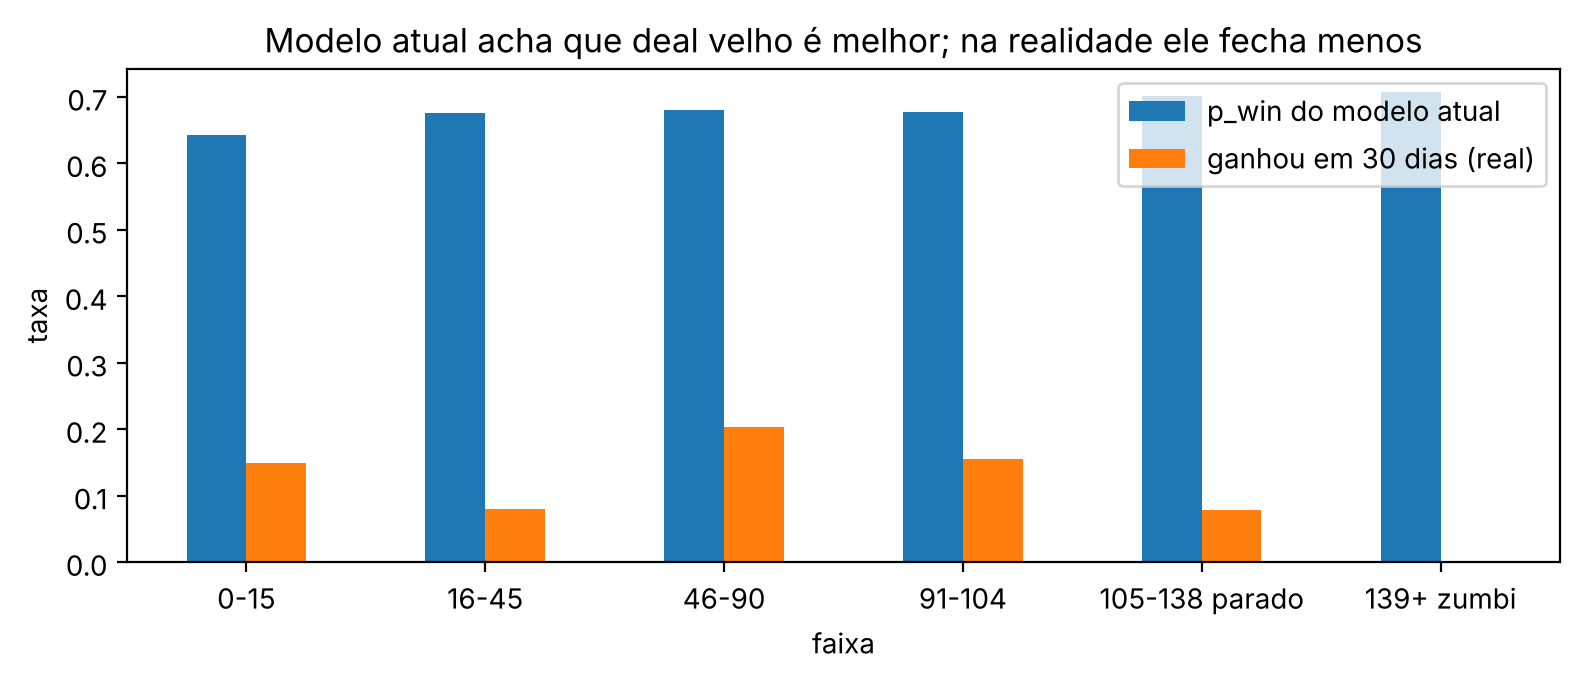

In [4]:
ax = tab[["p_win_atual", "real_ganhou_30d"]].plot(kind="bar", figsize=(8, 3.5), rot=0)
ax.set_title("Modelo atual acha que deal velho é melhor; na realidade ele fecha menos")
ax.set_ylabel("taxa"); ax.legend(["p_win do modelo atual", "ganhou em 30 dias (real)"]); plt.tight_layout()

## 3. Modelo novo

Mudanças em relação ao atual (o resto é igual: mesmas features point-in-time de `lead_core.features`, mesmo LightGBM):

| | Atual | Novo |
|---|---|---|
| Alvo | terminou Won (só deals já fechados) | ganhou em até 30 dias a partir da foto (todos os deals abertos) |
| Fotos de treino | semanais até T − 60 | semanais até T − 30 (o rótulo de 30 dias já é conhecido) |
| Feature extra | — | `age_vs_max_cycle` = idade / P99 do ciclo dos deals fechados até a foto |
| Parada antecipada | logloss | AUC (o logloss piora só porque a taxa base muda com o tempo) |
| Calibração | encolhimento para a média | Platt na janela de validação mais recente |
| Score | percentil de p_win × preço | percentil de p30 × preço |

In [5]:
HORIZON = 30
FEATURES = NUM_FEATURES + ["age_vs_max_cycle"] + CAT_FEATURES

def _logit(p):
    p = np.clip(p, 1e-4, 1 - 1e-4); return np.log(p / (1 - p))

def features_at(df, Tk):
    """Features point-in-time de todos os deals Engaging abertos em Tk (reaproveita lead_core)."""
    s = add_history_features(open_snapshot(df, Tk), df, Tk)
    closed = df[df["won"].notna() & (df["close_date"] <= Tk)]
    max_cycle = max(float((closed["close_date"] - closed["engage_date"]).dt.days.quantile(0.99)), 1.0)  # robusto a limpeza de zumbis
    return s.assign(age_vs_max_cycle=s["age_days"] / max_cycle)

def label_30d(s, Tk, h=HORIZON):
    return ((s["won"] == 1) & (s["close_date"] <= Tk + pd.Timedelta(days=h))).astype(int)

def build_train(df, T, h=HORIZON):
    start = df["close_date"].min() + pd.Timedelta(days=TRAIN_START_OFFSET_DAYS)
    parts = []
    for Tk in pd.date_range(start, T - pd.Timedelta(days=h), freq="7D"):
        s = features_at(df, Tk); s["y"] = label_30d(s, Tk, h); parts.append(s)
    return pd.concat(parts, ignore_index=True)

def matrix(f, cats):
    X = f[FEATURES].copy()
    for c in CAT_FEATURES:
        X[c] = pd.Categorical(X[c].astype(str), categories=cats[c])
    return X

def fit(df, T):
    tr = build_train(df, T)
    cats = {c: sorted(tr[c].dropna().astype(str).unique()) for c in CAT_FEATURES}
    X, y = matrix(tr, cats), tr["y"].to_numpy()
    snaps = np.sort(tr["snapshot"].unique()); val = (tr["snapshot"] >= snaps[int(len(snaps) * .75)]).to_numpy()
    probe = lgb.LGBMClassifier(n_estimators=800, **LGBM_PARAMS).fit(
        X[~val], y[~val], eval_set=[(X[val], y[val])], eval_metric="auc",
        callbacks=[lgb.early_stopping(50, first_metric_only=True, verbose=False)])
    best = max(int(probe.best_iteration_ or 0), 50)
    platt = LogisticRegression().fit(_logit(probe.predict_proba(X[val], num_iteration=best)[:, 1]).reshape(-1, 1), y[val])
    final = lgb.LGBMClassifier(n_estimators=best, **LGBM_PARAMS).fit(X, y)
    return {"model": final, "platt": platt, "cats": cats, "best": best, "rows": len(tr), "val_auc": float(roc_auc_score(y[val], probe.predict_proba(X[val], num_iteration=best)[:, 1]))}

def score(m, df, T):
    s = features_at(df, T)
    raw = m["model"].predict_proba(matrix(s, m["cats"]))[:, 1]
    p30 = m["platt"].predict_proba(_logit(raw).reshape(-1, 1))[:, 1]
    ev30 = p30 * s["price"].to_numpy(float)
    out = s[["opportunity_id", "sales_agent", "product", "price", "age_days"]].copy()
    out["p30"], out["ev30"] = p30, ev30
    out["score"] = score_from_ev(ev30, np.sort(ev30))          # 0-100, percentil da receita esperada em 30d
    return out.set_index("opportunity_id")

m = fit(df, T_NOW)
print({k: m[k] for k in ("best", "rows", "val_auc")})

{'best': 50, 'rows': 74494, 'val_auc': 0.6816853020381034}


### Importância e curva de idade do modelo novo

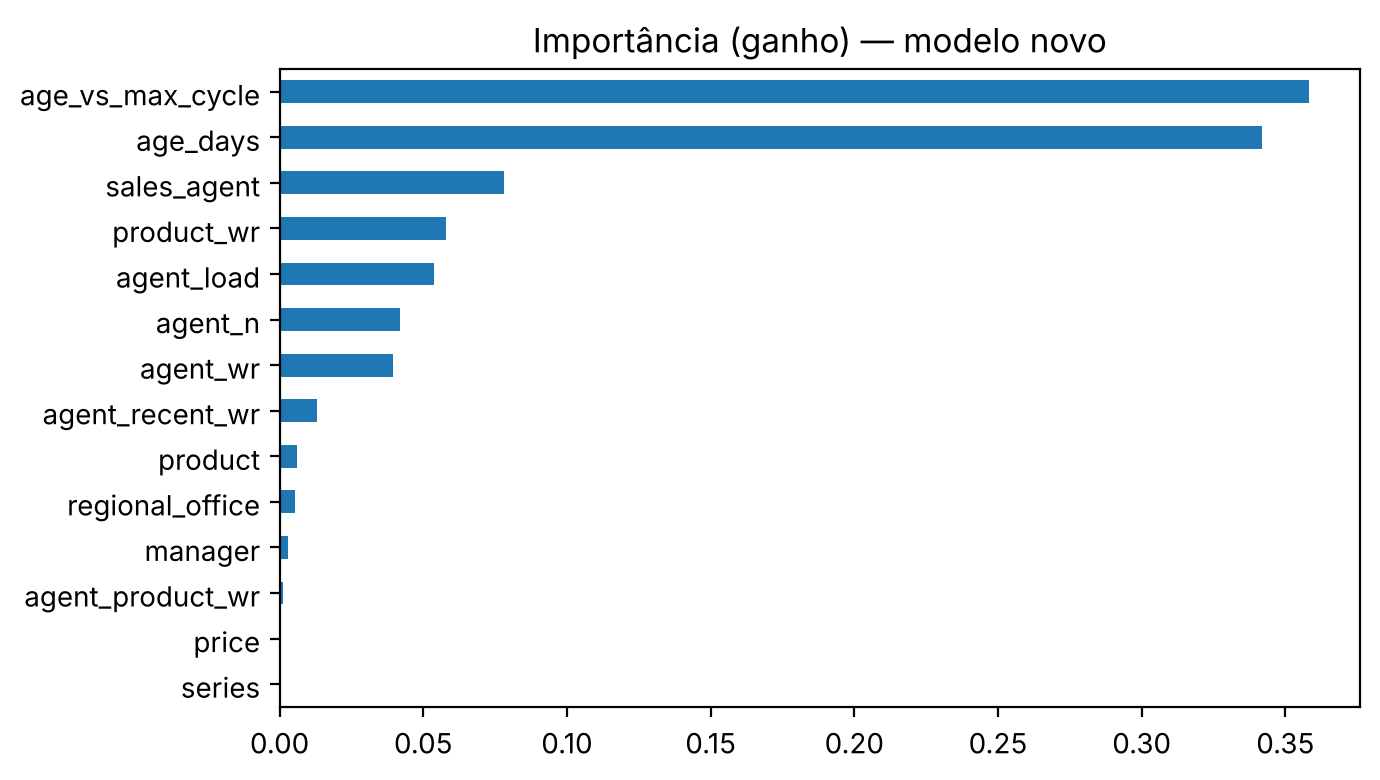

In [6]:
imp = pd.Series(m["model"].booster_.feature_importance("gain"), index=FEATURES).sort_values()
ax = (imp / imp.sum()).plot(kind="barh", figsize=(7, 4)); ax.set_title("Importância (ganho) — modelo novo"); plt.tight_layout()

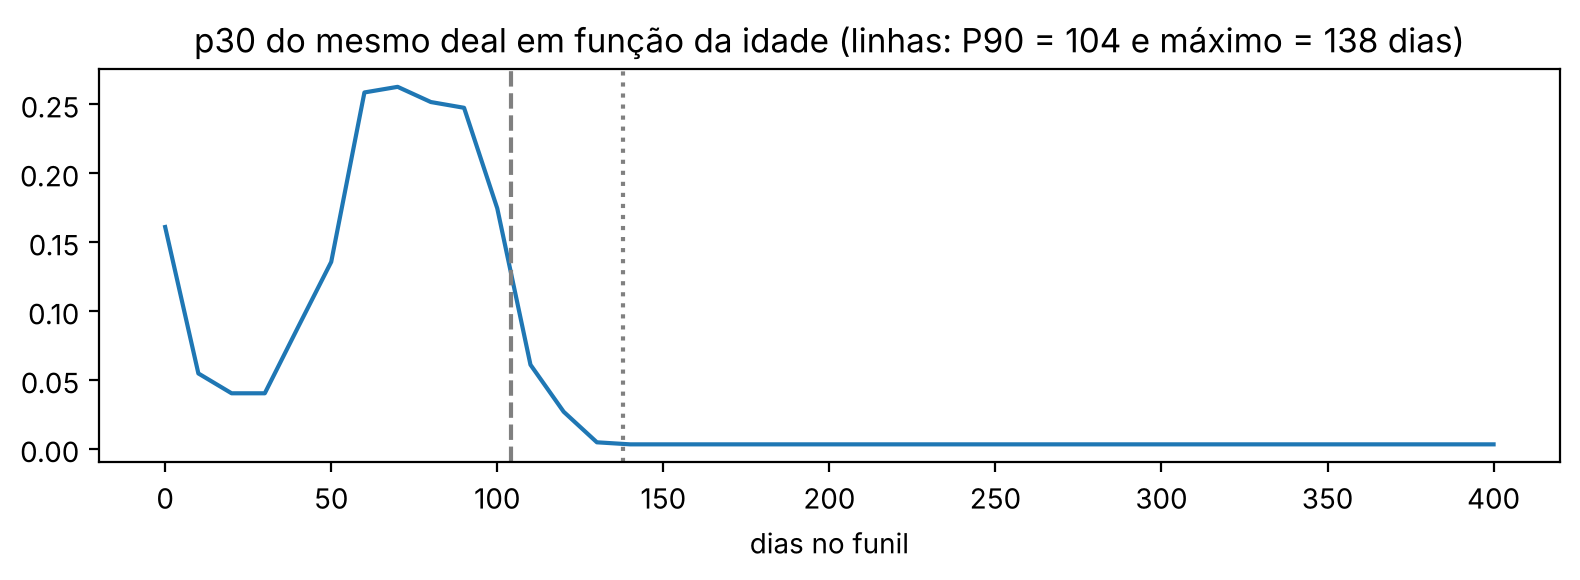

In [7]:
base = features_at(df, T_NOW).iloc[[0]]
curve = []
for a in range(0, 401, 10):
    r = base.copy(); r["age_days"] = a; r["age_vs_max_cycle"] = a / 127
    curve.append(m["platt"].predict_proba(_logit(m["model"].predict_proba(matrix(r, m["cats"]))[:, 1]).reshape(-1, 1))[0, 1])
ax = pd.Series(curve, index=range(0, 401, 10)).plot(figsize=(8, 3)); ax.axvline(104, ls="--", c="gray"); ax.axvline(138, ls=":", c="gray")
ax.set_title("p30 do mesmo deal em função da idade (linhas: P90 = 104 e máximo = 138 dias)"); ax.set_xlabel("dias no funil"); plt.tight_layout()

## 4. Backtest em dados reais contra o score atual
13 datas (a cada 14 dias, jun–nov/2017). Em cada data todos os modelos treinam só com o passado. Leva ~1 min.

In [8]:
from model_lab import backtest_real
bt = backtest_real.run(df, log=lambda *a: None)
resumo = backtest_real.summarize(bt)
resumo.round(3)

,auc_won_h,precision_top20,lift_top20,rev_capture_top20,stale_share_top20,zombie_share_top20,seller_top5_win_rate,seller_top5_revenue
abordagem,,,,,,,,
novo_receita_30d,0.652,0.198,1.621,0.644,0.095,0.000,0.224,183417.000
atual_score_lista,0.611,0.154,1.222,0.564,0.140,0.000,0.163,148362.154
atual_valor_esperado,0.492,0.116,0.921,0.443,0.340,0.240,0.127,114457.385
so_preco,0.501,0.113,0.890,0.431,0.399,0.271,0.126,113929.154
novo_conversao_30d,0.712,0.216,1.707,0.332,0.117,0.000,0.265,106139.615


datas em que o novo (receita) vence o atual no top-5 do vendedor: 12 de 13


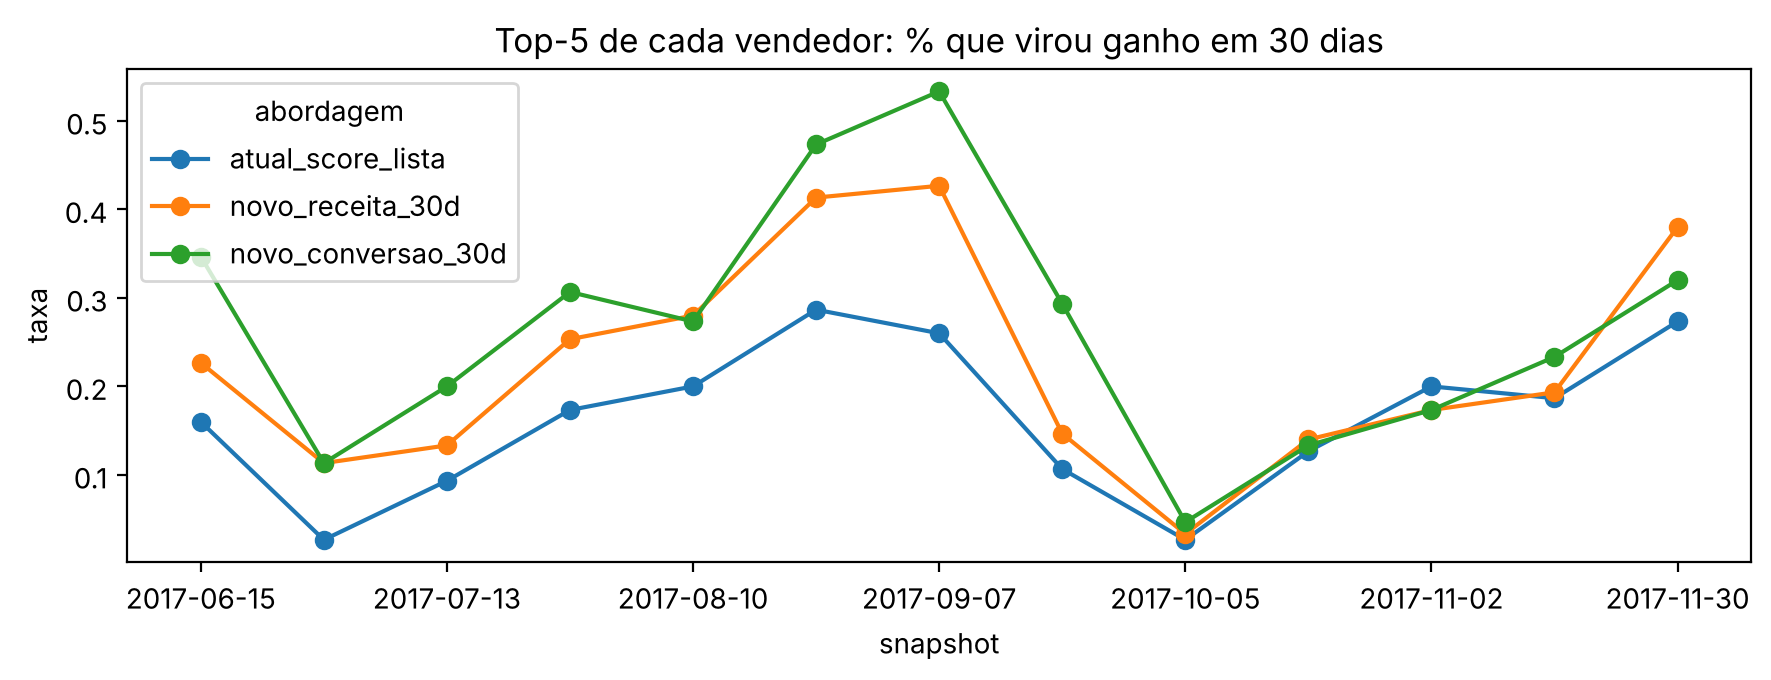

In [9]:
pv = bt.pivot(index="snapshot", columns="abordagem", values="seller_top5_win_rate")
ax = pv[["atual_score_lista", "novo_receita_30d", "novo_conversao_30d"]].plot(figsize=(9, 3.5), marker="o")
ax.set_title("Top-5 de cada vendedor: % que virou ganho em 30 dias"); ax.set_ylabel("taxa"); plt.tight_layout()
print("datas em que o novo (receita) vence o atual no top-5 do vendedor:", int((pv.novo_receita_30d > pv.atual_score_lista).sum()), "de", len(pv))

## 5. Regras de negócio propostas para o novo score
Validadas com o parecer do vendedor sênior. O `maior ciclo` deixa de ser o máximo histórico (que pula quando alguém limpa zumbis antigos)
e passa a ser um percentil robusto, congelado por versão do modelo.

In [10]:
def proposed_band(stage, age, score, thr):
    if stage == "Prospecting":            return "prospecting"
    if age > thr["review_days"]:          return "review"       # zumbi: sugerir encerrar em lote
    if age > thr["stale_days"]:           return "stale_risk"   # Decidir: fila própria, score só ordena, nunca Alta
    if score >= 80:                       return "focus"
    if score >= 40:                       return "follow_up"
    return "low"

def robust_thresholds(df, T):
    c = df[df["won"].notna() & (df["close_date"] <= T)]
    d = (c["close_date"] - c["engage_date"]).dt.days
    return {"typical_p50": int(d.quantile(.5)), "stale_days": int(d.quantile(.9)), "review_days": int(d.quantile(.99))}

thr = robust_thresholds(df, T_NOW); thr

{'typical_p50': 45, 'stale_days': 104, 'review_days': 127}

## 6. Pipeline de hoje pontuado pelo modelo novo

In [11]:
today = score(m, df, T_NOW)
today["band"] = [proposed_band("Engaging", a, s, thr) for a, s in zip(today["age_days"], today["score"])]
print(today["band"].value_counts().to_dict())
cols = ["sales_agent", "product", "age_days", "band", "score", "p30", "ev30"]
today[today["band"] == "focus"].sort_values("ev30", ascending=False)[cols].head(15).round(3)

{'review': 1346, 'focus': 119, 'stale_risk': 91, 'follow_up': 24, 'low': 9}


,sales_agent,product,age_days,band,score,p30,ev30
opportunity_id,,,,,,,
1LY8CAXD,Rosalina Dieter,GTK 500,95,focus,100,0.132,3546.714
YQJGEI71,James Ascencio,GTX Plus Pro,73,focus,100,0.212,1163.116
NX28C8EI,James Ascencio,GTX Plus Pro,92,focus,100,0.201,1104.576
QNB3SCN9,Wilburn Farren,GTX Plus Pro,91,focus,100,0.191,1047.752
9JTFD4FZ,Wilburn Farren,GTX Plus Pro,94,focus,100,0.190,1039.175
HN6TZPAF,Wilburn Farren,GTX Plus Pro,61,focus,100,0.187,1022.631
NNNEMOZ5,James Ascencio,GTX Plus Pro,56,focus,100,0.185,1016.785
JJGRAQ2K,Kary Hendrixson,GTX Plus Pro,69,focus,100,0.180,986.393
OMCFUDOU,James Ascencio,GTX Pro,61,focus,99,0.198,952.526


In [12]:
vicki = today[today["sales_agent"] == "Vicki Laflamme"].sort_values("ev30", ascending=False)
vicki[cols].head(10).round(3)

,sales_agent,product,age_days,band,score,p30,ev30
opportunity_id,,,,,,,
E2CJIO85,Vicki Laflamme,GTX Plus Pro,89,focus,97,0.088,484.420
DYYJW46L,Vicki Laflamme,GTX Plus Pro,78,focus,97,0.088,479.922
X7MN9ROG,Vicki Laflamme,GTX Plus Pro,69,focus,97,0.088,479.922
4SOUOUKH,Vicki Laflamme,GTX Plus Pro,92,focus,97,0.087,477.265
DY8DMZZ9,Vicki Laflamme,GTX Plus Pro,106,stale_risk,96,0.060,328.796
6JBM1ZKO,Vicki Laflamme,GTX Pro,52,focus,96,0.063,305.852
3Q15OHQB,Vicki Laflamme,MG Advanced,99,focus,96,0.084,284.592
2FM8HJDM,Vicki Laflamme,MG Advanced,102,focus,95,0.075,253.323
Y3AAS62P,Vicki Laflamme,GTX Plus Basic,110,stale_risk,90,0.050,55.240


## 7. Checklist para levar ao backend
1. `lead_trainer/training.py`: `build_train_30d` (fotos até T−30, alvo `won_within_30d`, todos os deals abertos).
2. `lead_core/features.py`: feature `age_vs_max_cycle` = idade / P99 do ciclo (point-in-time; também no what-if).
3. `lead_trainer/calibration.py`: Platt na validação; `calibration.useful` continua decidindo se a probabilidade aparece.
4. `lead_core/bands.py`: limiares por percentil robusto (P90 / P99), congelados no model card; stale nunca é prioridade Alta.
5. `lead_trainer/evaluation.py`: backtest com datas **móveis** (últimas 4 fotos até T−30) e métricas de vendedor (receita top-20%, acerto top-5).
6. `quality_gate`: promover só se o desafiante não perder do campeão em receita top-20% e top-5 nas datas recentes.
7. Contrato da API intacto (`score`, `band`, `expected_value`, `p_win`); `expected_value` passa a significar *receita esperada em 30 dias* — atualizar o texto do model card e do "Como funciona".
8. Rodar `model-lab` (pytest) a cada novo lote de dados antes de promover.